# 02 · Download the bands and convert them to reflectance

**Goal:** get the 6 bands we need for both dates, on **exactly the same pixel grid**, as *reflectance*.

**Key ideas:**
- A satellite image is a stack of **bands**. Each band is a grid of numbers measuring one colour of light (some invisible to us, like near-infrared).
- The files store **digital numbers (DN)**, whole numbers that save space. For Sentinel-2 L2A (since 2022):
  `reflectance = (DN − 1000) / 10000`
  **Reflectance** (0–1) = the fraction of sunlight the ground bounces back. That's what the indices need. This is the same idea as the course's Landsat formula `DN × 0.0000275 − 0.2`, with Sentinel-2's own numbers.
- Some bands are 10 m and some are 20 m. We resample all of them to one **10 m grid**, and put the post-fire image on *exactly* the same pixels as the pre-fire one, so we can subtract them pixel by pixel.

In [1]:
import matplotlib.pyplot as plt
from common import *

scenes = load_json("step1_scenes.json", "01")
print("Pre:", scenes["pre"]["date"], "  Post:", scenes["post"]["date"])

Pre: 2026-06-24   Post: 2026-08-08


## 1. Helper functions
- `s2_offset` checks the image's processing version to know whether the −1000 offset applies.
- `to_reflectance` applies the formula, marks 0 as *no data* (NaN = "not a number") and turns tiny negatives into 0 (course: `Con(x<0, 0, x)`).
- `load_date` downloads only the AOI window of each band.

In [2]:
def s2_offset(items) -> int:
    vals = []
    for it in items:
        try:
            vals.append(float(it.properties.get("s2:processing_baseline")))
        except (TypeError, ValueError):
            pass
    return -1000 if (not vals or max(vals) >= 4.0) else 0


def to_reflectance(dn: np.ndarray, offset: int) -> np.ndarray:
    dn = dn.astype("float32")
    r = (dn + offset) / 10000.0
    r[dn == 0] = np.nan                  # 0 = no data
    return np.clip(r, 0, None)           # tiny negatives -> 0


def load_date(items, geobox=None):
    import odc.stac
    names = list(BANDS.values()) + [QA_BAND]
    kw = dict(bands=names, groupby="solar_day",
              resampling={QA_BAND: "nearest", "*": "bilinear"})
    if geobox is None:
        kw.update(bbox=CFG["bbox"], crs=CFG["crs"], resolution=CFG["resolution"])
    else:
        kw.update(geobox=geobox)         # snap onto an existing grid
    ds = odc.stac.load(items, **kw).isel(time=0)
    off = s2_offset(items)
    refl = {role: to_reflectance(ds[b].values, off) for role, b in BANDS.items()}
    return ds, refl, ds[QA_BAND].values

## 2. Download (takes 1–3 minutes)
The pre-fire image defines the grid (`geobox` = the pixel layout: size, position, projection). The post-fire image is then loaded **onto that same geobox**.

In [3]:
catalog = open_catalog()
items = {k: list(catalog.search(collections=[COLLECTION], ids=scenes[k]["ids"]).items())
         for k in ("pre", "post")}

ds, pre, scl0 = load_date(items["pre"])
grid = ds.odc.geobox
transform = getattr(grid, "transform", None) or grid.affine
_, post, scl1 = load_date(items["post"], geobox=grid)

h, w = scl0.shape
print(f"Grid: {h} rows × {w} columns of {CFG['resolution']} m = {h * w * CFG['resolution']**2 / 1e6:.1f} km²")

Grid: 4112 rows × 6860 columns of 10 m = 2820.8 km²


## 3. Look inside: one band is just a grid of numbers
Below are the top-left 4 × 4 pixels of the pre-fire red band, then the same band drawn as an image.

[[0.153 0.15  0.16  0.174]
 [0.165 0.147 0.155 0.177]
 [0.156 0.141 0.136 0.159]
 [0.154 0.135 0.118 0.138]]


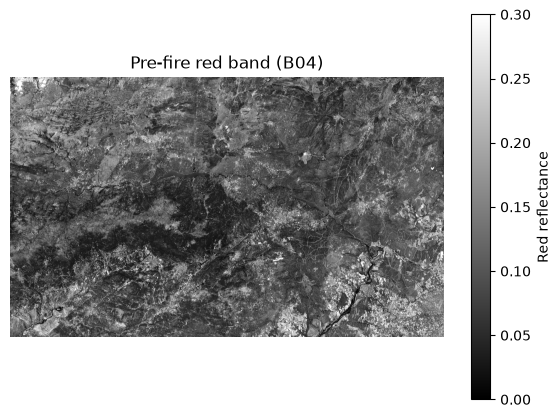

In [4]:
print(np.round(pre["red"][:4, :4], 3))
plt.figure(figsize=(7, 5))
plt.imshow(pre["red"], cmap="gray", vmin=0, vmax=0.3)
plt.colorbar(label="Red reflectance")
plt.title("Pre-fire red band (B04)"); plt.axis("off"); plt.show()

## 4. Valid-pixel mask
We exclude pixels that are cloud, snow or no-data on **either** date, plus water (the reservoirs). Otherwise they would look like "change".
White = valid, black = excluded.

Valid: 98.8 %   water: 0.42 %


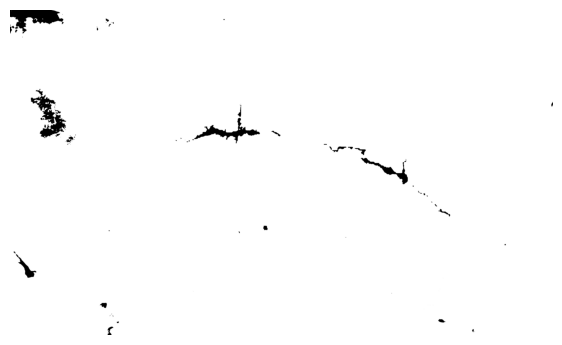

In [5]:
valid = ~(np.isin(scl0, SCL_NODATA + SCL_CLOUD + SCL_SNOW)
          | np.isin(scl1, SCL_NODATA + SCL_CLOUD + SCL_SNOW)
          | np.isin(scl0, SCL_WATER))
for b in ("red", "nir10", "nir", "swir2"):
    valid &= np.isfinite(pre[b]) & np.isfinite(post[b])

print(f"Valid: {valid.mean() * 100:.1f} %   water: {np.isin(scl0, SCL_WATER).mean() * 100:.2f} %")
plt.figure(figsize=(7, 5)); plt.imshow(valid, cmap="gray"); plt.axis("off"); plt.show()

## 5. False-colour 8-4-3: the burn scar appears
Bands shown as **R = NIR (B8), G = Red (B4), B = Green (B3)**. Healthy vegetation reflects a lot of near-infrared, so it looks **red**. A burn scar has lost its leaves, so it looks **dark brown/black**.
Both images use the *same* colour stretch so they can be compared fairly.

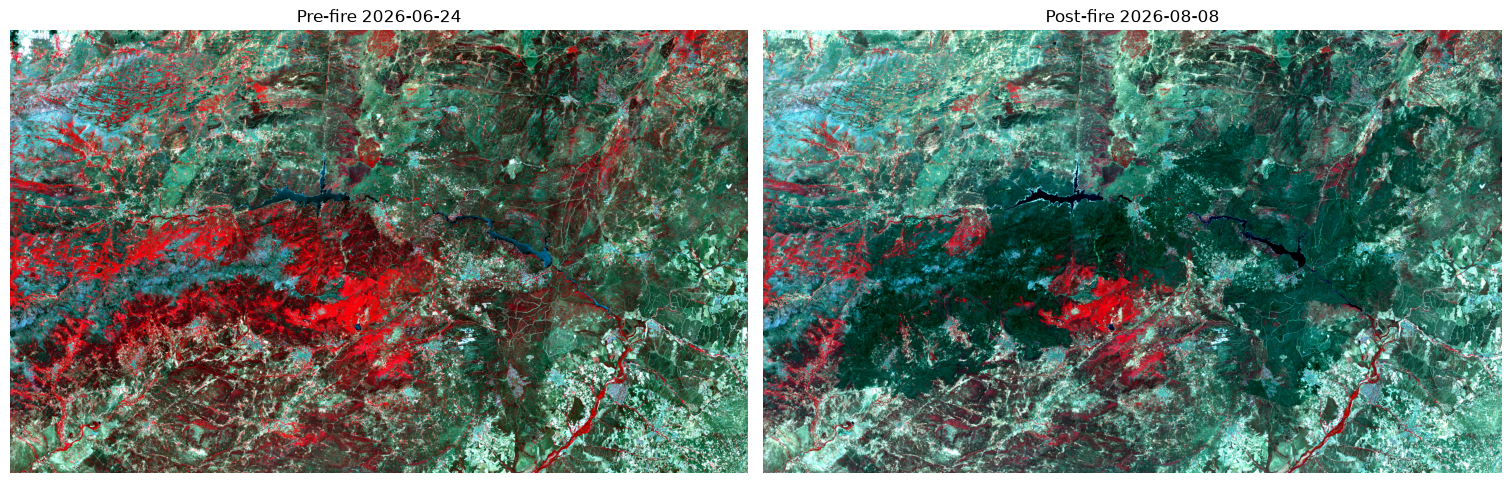

In [6]:
img0, img1, lo, hi = false_color(pre, post)
fig, ax = plt.subplots(1, 2, figsize=(15, 7), constrained_layout=True)
ax[0].imshow(img0); ax[0].set_title(f"Pre-fire {scenes['pre']['date']}")
ax[1].imshow(img1); ax[1].set_title(f"Post-fire {scenes['post']['date']}")
for a in ax:
    a.set_axis_off()
fig.savefig(OUT / "step2_false_color_843.png", dpi=130)
plt.show()

## 6. Save everything as GeoTIFFs (open them in ArcGIS Pro too)

In [7]:
roles = list(BANDS)
names = [f"{r} ({BANDS[r]})" for r in roles]
write_tif(OUT / "pre_reflectance.tif", [pre[r] for r in roles], transform, CFG["crs"], np.nan, names)
write_tif(OUT / "post_reflectance.tif", [post[r] for r in roles], transform, CFG["crs"], np.nan, names)
write_tif(OUT / "valid_mask.tif", valid.astype("uint8"), transform, CFG["crs"], 255)
for name, b in (("pre", pre), ("post", post)):
    write_tif(OUT / f"{name}_fire_843.tif", [b["nir10"], b["red"], b["green"]],
              transform, CFG["crs"], np.nan, ["NIR B8", "Red B4", "Green B3"])
write_tif(OUT / "nir_change_composite.tif", [pre["nir10"], post["nir10"], pre["nir10"]],
          transform, CFG["crs"], np.nan, ["NIR pre", "NIR post", "NIR pre"])

info = {"grid": {"rows": h, "cols": w, "pixel_m": CFG["resolution"], "crs": CFG["crs"],
                 "aoi_km2": round(h * w * CFG["resolution"] ** 2 / 1e6, 2),
                 "transform": list(transform)[:6]},
        "valid_pct": round(float(valid.mean() * 100), 2),
        "arcgis_stretch_843": {"Band_1 NIR": [round(float(lo[0]), 3), round(float(hi[0]), 3)],
                               "Band_2 Red": [round(float(lo[1]), 3), round(float(hi[1]), 3)],
                               "Band_3 Green": [round(float(lo[2]), 3), round(float(hi[2]), 3)]}}
save_json(info, "step2_info.json")
print("Saved to", OUT.name)

Saved to outputs_madrid_avila


## What you learned
- A band is a **grid of numbers**, and an image is a **stack of bands**.
- Files store compact integers (DN). We convert them to **reflectance** before doing any science with them.
- To compare two dates, both must sit on the **same pixel grid**.
- **False colour** uses invisible light (NIR) to make vegetation and burn scars obvious.

**Next:** `03_indices.ipynb`